In [62]:
import pandas as pd
from pandas.api.types import CategoricalDtype
from plotnine import *

# Global Data Pre-processing

In [236]:
mpc  = pd.read_csv('../saved_runs/data/mpc_results.csv')
mpc['type'] = 'MPC'
mpc.drop(columns='Unnamed: 0', inplace=True)

tmpc = pd.read_csv('../saved_runs/data/tmpc_results.csv')
tmpc['type'] = 'TMPC'
tmpc.drop(columns='Unnamed: 0', inplace=True)

sdd = pd.read_csv('../saved_runs/data/sdd_results.csv')
sdd['type'] = 'SDD-TMPC'
sdd.drop(columns='Unnamed: 0', inplace=True)

data = pd.concat([mpc, tmpc, sdd])
data.reset_index(drop=True, inplace=True)

order = CategoricalDtype(
    categories=['MPC', 'TMPC', 'SDD-TMPC'],
    ordered=True
)
data['type'] = data['type'].astype(order)

def theme_poster(fig_size: tuple[int, int]): 
    return theme(
        figure_size=fig_size,
        text=element_text(colour='white'),
        
        legend_background=element_blank(),
        legend_position='right',
        
        panel_background=element_rect(fill="#00000000"),
        panel_border=element_rect(colour='#F0F0F0'),
        plot_background=element_rect(fill="#0C2340", colour='#00000000'),
        strip_background=element_rect(fill="#00000000", colour='#00000000'),

        axis_ticks_major=element_blank(),
        panel_grid_major=element_line(size=0.4, colour='#F0F0F0'),
        panel_grid_minor=element_line(size=0.2, colour='#F0F0F0'),
    )

# Collisions
### Data Handling

In [ ]:
collisions = data[['wall_collisions', 'victims_collisions', 'fire_collisions', 'type']]
collisions.columns = ['Terrain', 'Victim', 'Fire', 'type']
collisions = collisions.melt(id_vars='type', value_name='collisions', value_vars=['Terrain', 'Victim', 'Fire'], var_name='collision_type')
# collisions['total'] = collisions['Terrain'] + collisions['Victim'] + collisions['Fire']
# collisions = collisions[['total', 'type']]

### Plotting

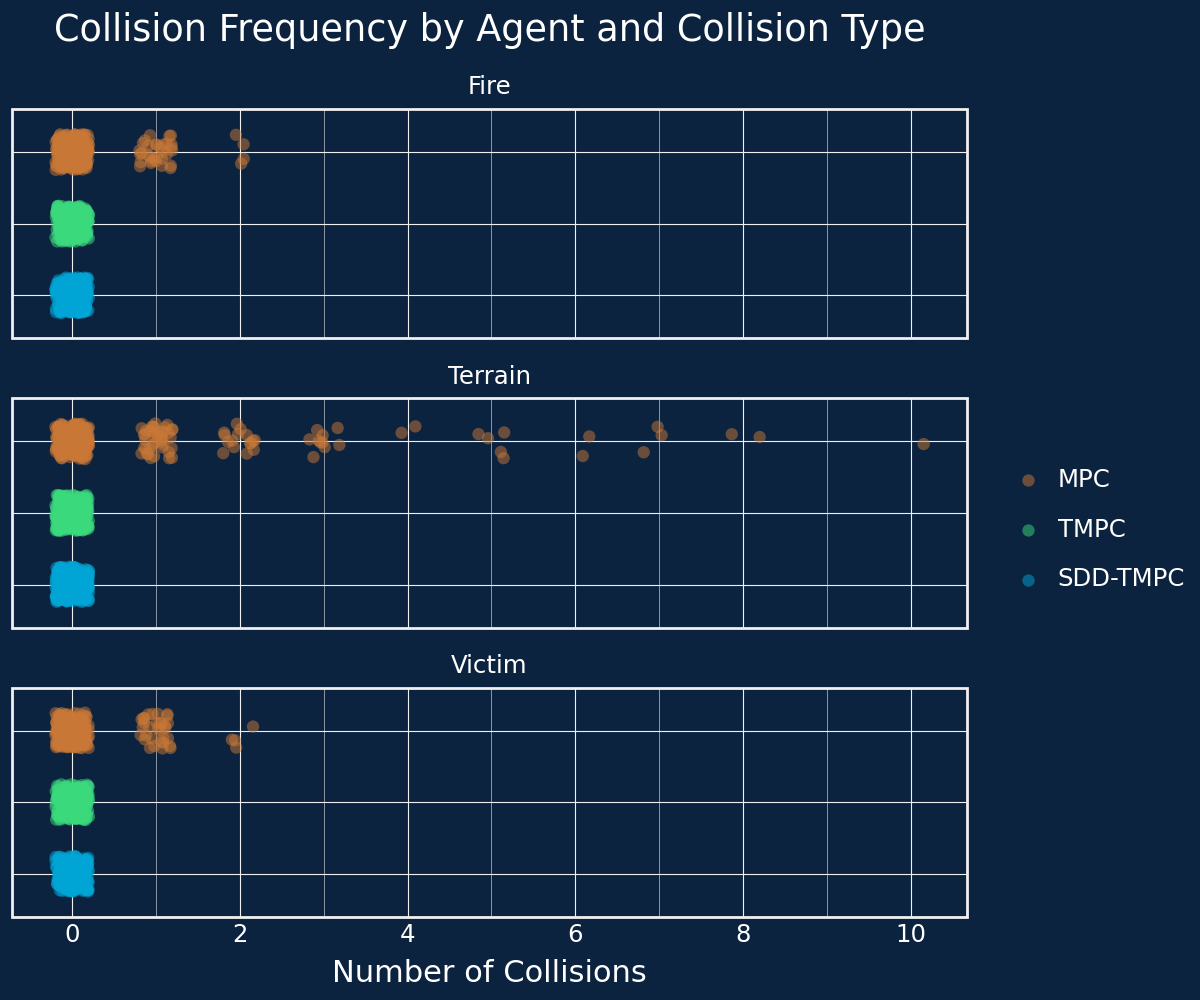

In [337]:
(
    ggplot(collisions, aes(x='type', y='collisions', fill='type'))
           + geom_jitter(width=0.25, height=0.2, alpha=0.5, size=2, colour='#00000000')
           + coord_flip()
           + facet_wrap('collision_type', nrow=3)
           + labs(x='', y='Number of Collisions', title='Collision Frequency by Agent and Collision Type', size='Number of Runs', fill='')
           + scale_x_discrete(limits=['SDD-TMPC', 'TMPC', 'MPC'])
           + scale_y_continuous(breaks=range(0,12,2))
           + scale_fill_manual(values=["#C97836", "#3BDA7D", "#01A6D6"])
           + scale_size_continuous(range=(1,15), guide=None)
           + theme_poster((6, 5))
           + theme(axis_text_y=element_blank())
) 

# Run Time

### Data Handling

In [290]:
runtimes = data[['outcome', 'duration', 'type']]
runtimes.columns = ['Outcome', 'Duration', 'type']

success = runtimes[runtimes['Outcome']=='SUCCESS'].groupby(['type', 'Outcome']).count().reset_index()
success['Duration'] /= mpc.shape[0]

### Plotting

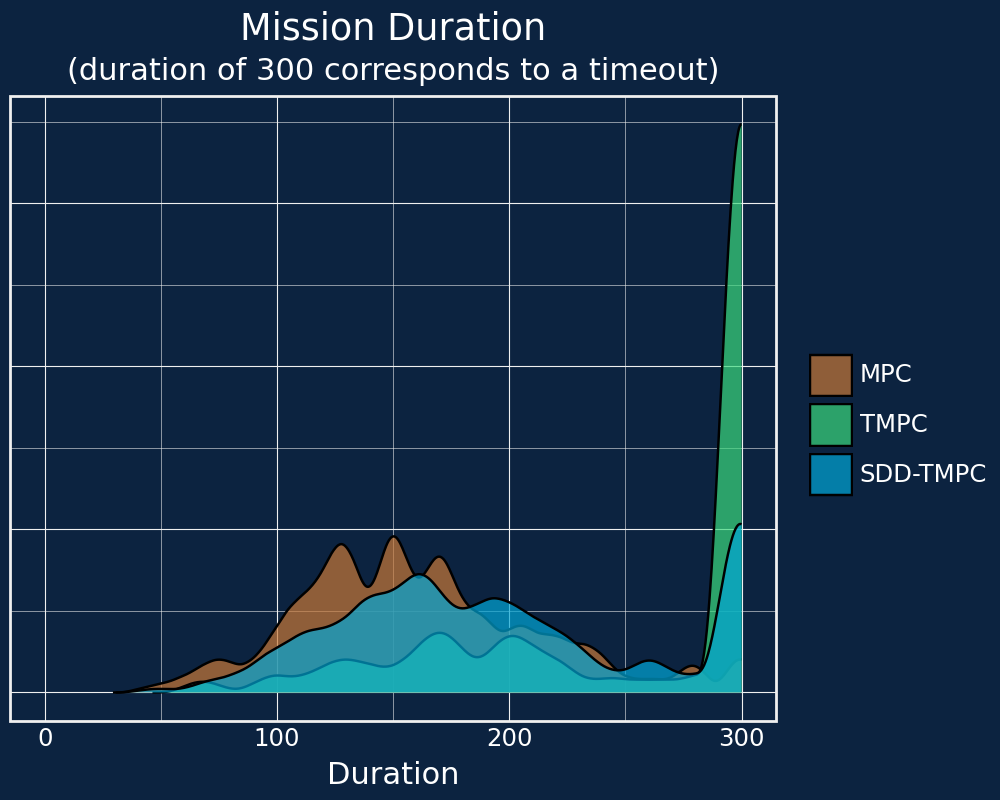

In [291]:
(
    ggplot(runtimes, aes(x='Duration', fill='type'))
           + geom_density(kernel='triw', position='identity', alpha=0.7)
           + labs(x='Duration', y='', title='Mission Duration', subtitle='(duration of 300 corresponds to a timeout)', fill='')
           + scale_fill_manual(values=["#C97836", "#3BDA7D", "#01A6D6"])
           + scale_x_continuous(limits=(0, 300))
           + theme_poster((5, 4))
           + theme(plot_title=element_text(ha='center'),
                   plot_subtitle=element_text(ha='center'),
                   axis_text_y=element_blank(),
                   axis_ticks_y=element_blank()
           )
)

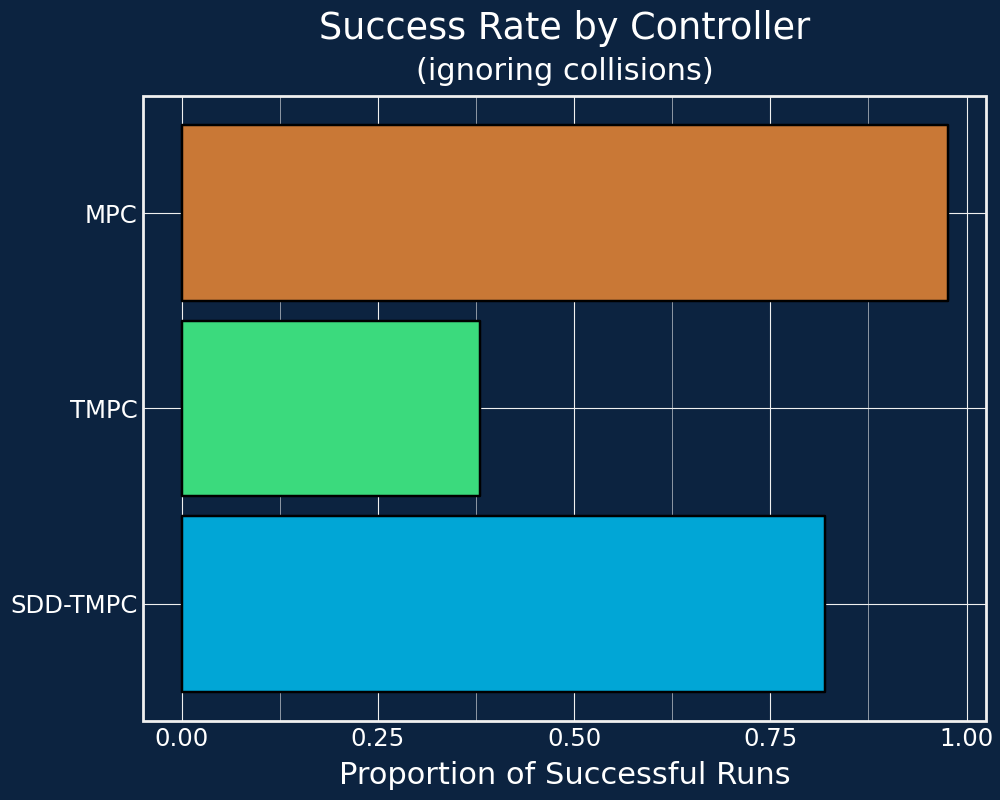

In [ ]:
(
    ggplot(success, aes(x='type', y='Duration', fill='type'))
           + geom_col(colour='black')
           + coord_flip()
           + labs(x='', y='Proportion of Successful Runs', title='Success Rate by Controller', subtitle='(ignoring collisions)', fill='')
           + scale_x_discrete(limits=['SDD-TMPC', 'TMPC', 'MPC'])
           + scale_fill_manual(values=["#C97836", "#3BDA7D", "#01A6D6"], guide=None)
           + theme_poster((5, 4))
           + theme(plot_title=element_text(ha='center'), plot_subtitle=element_text(ha='center'))
)